In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
import joblib

In [2]:
df = pd.read_csv("ford.csv")

df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [3]:
df.isnull().value_counts()

model  year   price  transmission  mileage  fuelType  tax    mpg    engineSize
False  False  False  False         False    False     False  False  False         17966
Name: count, dtype: int64

In [4]:
df.duplicated().value_counts()

False    17812
True       154
Name: count, dtype: int64

In [5]:
df[df.duplicated()]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
159,Focus,2016,10995,Manual,30923,Diesel,0,74.3,1.5
312,Focus,2019,14998,Manual,7000,Petrol,145,58.9,1.0
349,Focus,2019,14998,Manual,7000,Petrol,145,58.9,1.0
510,EcoSport,2019,15489,Manual,5636,Diesel,145,68.9,1.5
512,Grand Tourneo Connect,2019,19999,Manual,3500,Diesel,145,61.4,1.5
...,...,...,...,...,...,...,...,...,...
14556,Mondeo,2015,6793,Manual,138000,Diesel,20,68.9,2.0
15121,Kuga,2017,14999,Manual,24877,Diesel,30,64.2,1.5
15127,EcoSport,2019,16799,Automatic,433,Petrol,150,45.6,1.0
15685,KA,2008,1795,Manual,63000,Petrol,160,45.6,1.3


In [6]:
df = df.drop_duplicates()

In [7]:
df.columns = df.columns.str.strip()

In [8]:
print("Shape: ", df.shape)

Shape:  (17812, 9)


In [9]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [10]:
df.dtypes

model               str
year              int64
price             int64
transmission        str
mileage           int64
fuelType            str
tax               int64
mpg             float64
engineSize      float64
dtype: object

In [11]:
catColumns = ["model", "fuelType", "transmission"]

for c in catColumns:
    df[c] = df[c].astype("string")

df.dtypes

model            string
year              int64
price             int64
transmission     string
mileage           int64
fuelType         string
tax               int64
mpg             float64
engineSize      float64
dtype: object

In [12]:
for c in catColumns:
    df[c] = df[c].str.strip()

df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


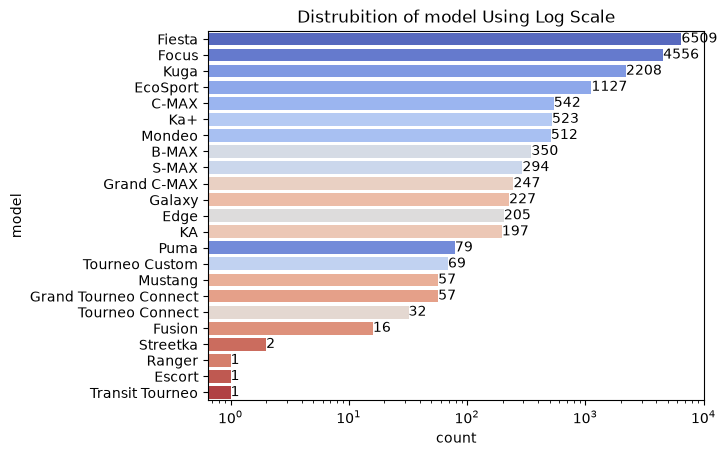

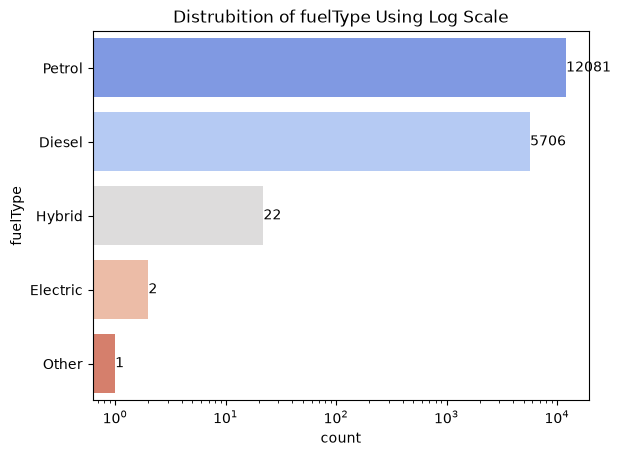

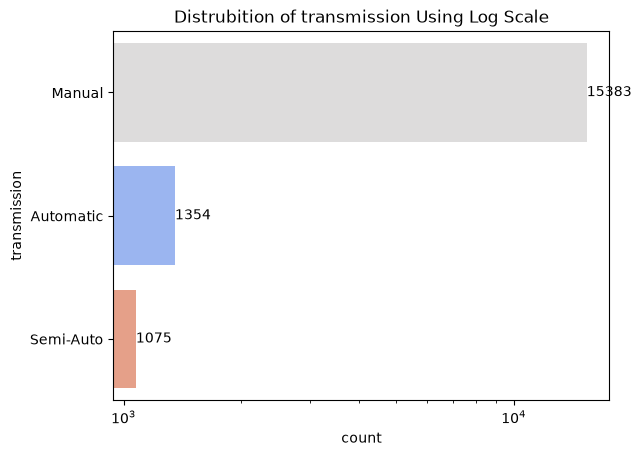

In [13]:
for c in catColumns:
    ax = sns.countplot(data=df, y=c, hue=c, palette="coolwarm", order=df[c].value_counts().index)
    ax.set_xscale("log")
    ax.set_title("Distrubition of " + c + " Using Log Scale")
    
    for container in ax.containers:
        ax.bar_label(container)
    
    plt.show()

In [14]:
df[df["fuelType"] == "Other"]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
17492,Mondeo,2015,13800,Automatic,19470,Other,0,67.3,2.0


In [15]:
df[df["model"] == "Mondeo"]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
35,Mondeo,2019,20000,Manual,24,Diesel,145,65.7,2.0
138,Mondeo,2015,9995,Manual,30753,Diesel,0,78.5,1.5
167,Mondeo,2016,9998,Manual,38358,Diesel,0,78.5,1.5
318,Mondeo,2017,17498,Semi-Auto,14569,Diesel,145,53.3,2.0
322,Mondeo,2019,22998,Automatic,7337,Hybrid,140,47.1,2.0
...,...,...,...,...,...,...,...,...,...
17711,Mondeo,2018,17999,Automatic,3570,Petrol,145,44.1,1.5
17751,Mondeo,2011,5495,Manual,104000,Diesel,200,47.1,2.2
17776,Mondeo,2016,10500,Manual,54004,Diesel,30,64.2,2.0
17823,Mondeo,2017,15499,Automatic,10162,Petrol,235,38.2,5.0


In [16]:
df["fuelType"] = df["fuelType"].replace("Other", "Hybrid")

In [17]:
df[df["model"] == "Mondeo"]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
35,Mondeo,2019,20000,Manual,24,Diesel,145,65.7,2.0
138,Mondeo,2015,9995,Manual,30753,Diesel,0,78.5,1.5
167,Mondeo,2016,9998,Manual,38358,Diesel,0,78.5,1.5
318,Mondeo,2017,17498,Semi-Auto,14569,Diesel,145,53.3,2.0
322,Mondeo,2019,22998,Automatic,7337,Hybrid,140,47.1,2.0
...,...,...,...,...,...,...,...,...,...
17711,Mondeo,2018,17999,Automatic,3570,Petrol,145,44.1,1.5
17751,Mondeo,2011,5495,Manual,104000,Diesel,200,47.1,2.2
17776,Mondeo,2016,10500,Manual,54004,Diesel,30,64.2,2.0
17823,Mondeo,2017,15499,Automatic,10162,Petrol,235,38.2,5.0


In [18]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17812.000000,17812.000000,17812.000000,17812.000000,17812.000000,17812.000000
mean,2016.862396,12269.556310,23381.146362,113.315012,57.908696,1.350623
std,2.052039,4736.285417,19419.011045,62.034603,10.132696,0.432581
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,10000.000000,30.000000,52.300000,1.000000
50%,2017.000000,11288.000000,18277.000000,145.000000,58.900000,1.200000
75%,2018.000000,15295.000000,31098.500000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [19]:
df[df["year"] > 2021]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
17726,Fiesta,2060,6495,Automatic,54807,Petrol,205,42.8,1.4


In [20]:
# the cars with these specifications are made between the years 2008-2017
# there is a similar car with almost this exact specifications that is made in 2015 so i will be giving it this year
# https://www.facebook.com/groups/653115531481737/posts/9352321668227703/

df["year"] = df["year"].replace(2060, 2015)

In [21]:
df[(df["model"] == "Fiesta") & (df["price"] == 6495)]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
844,Fiesta,2014,6495,Manual,54249,Petrol,30,54.3,1.2
1471,Fiesta,2016,6495,Manual,15083,Petrol,30,54.3,1.2
10374,Fiesta,2016,6495,Manual,47800,Petrol,0,65.7,1.0
11988,Fiesta,2015,6495,Manual,58693,Diesel,0,78.5,1.6
13262,Fiesta,2014,6495,Manual,44000,Petrol,30,54.3,1.2
13461,Fiesta,2014,6495,Manual,61713,Diesel,0,78.5,1.6
14860,Fiesta,2015,6495,Manual,41896,Petrol,125,54.3,1.2
15040,Fiesta,2013,6495,Manual,48704,Petrol,0,65.7,1.0
15697,Fiesta,2014,6495,Manual,46000,Petrol,30,54.3,1.2
16517,Fiesta,2016,6495,Manual,65000,Petrol,0,65.7,1.0


In [22]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17812.000000,17812.000000,17812.000000,17812.000000,17812.000000,17812.000000
mean,2016.859870,12269.556310,23381.146362,113.315012,57.908696,1.350623
std,2.026469,4736.285417,19419.011045,62.034603,10.132696,0.432581
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,10000.000000,30.000000,52.300000,1.000000
50%,2017.000000,11288.000000,18277.000000,145.000000,58.900000,1.200000
75%,2018.000000,15295.000000,31098.500000,145.000000,65.700000,1.500000
max,2020.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [23]:
price_q3 = df["price"].describe()["75%"]

print("Number of rows: ", df[df["price"] > price_q3]["price"].shape[0])
df[df["price"] > price_q3]["price"].describe()

Number of rows:  4447


count     4447.000000
mean     18677.765910
std       3613.207582
min      15298.000000
25%      16495.000000
50%      17750.000000
75%      19500.000000
max      54995.000000
Name: price, dtype: float64

In [24]:
df[df["price"] > 30000]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
230,S-MAX,2020,34498,Semi-Auto,4623,Diesel,145,43.5,2.0
302,Mustang,2020,42489,Automatic,3500,Petrol,145,22.1,5.0
339,Mustang,2020,38489,Automatic,3500,Petrol,145,30.7,2.3
354,Mustang,2018,31498,Automatic,6250,Petrol,145,23.5,5.0
387,Mustang,2019,39998,Automatic,5000,Petrol,145,22.6,5.0
...,...,...,...,...,...,...,...,...,...
17181,Edge,2019,33994,Automatic,14,Diesel,145,37.2,2.0
17193,Edge,2019,33495,Automatic,1,Diesel,145,37.2,2.0
17207,Mustang,2018,30500,Manual,5000,Petrol,145,20.9,5.0
17304,Mustang,2019,39995,Automatic,800,Petrol,145,22.1,5.0


In [25]:
print("Number of rows: ", df[df["price"] > 35000].shape[0])
df[df["price"] > 35000]

Number of rows:  31


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
302,Mustang,2020,42489,Automatic,3500,Petrol,145,22.1,5.0
339,Mustang,2020,38489,Automatic,3500,Petrol,145,30.7,2.3
387,Mustang,2019,39998,Automatic,5000,Petrol,145,22.6,5.0
1039,Focus,2017,38015,Manual,197,Diesel,145,74.3,1.5
2204,Mustang,2020,36500,Semi-Auto,672,Petrol,145,30.7,2.3
2264,Mustang,2020,39990,Semi-Auto,691,Petrol,145,22.1,5.0
5015,Mustang,2020,37990,Automatic,2450,Petrol,145,22.1,5.0
5342,Mustang,2019,37991,Automatic,1055,Petrol,145,22.1,5.0
5523,Mustang,2020,37990,Semi-Auto,151,Petrol,145,22.1,5.0
7164,Mustang,2020,40495,Semi-Auto,3200,Petrol,145,24.8,5.0


In [26]:
df[(df["price"] > 35000) & (df["engineSize"] == 5)].shape[0]

22

Text(0.5, 1.0, 'Correlaction Between Variables')

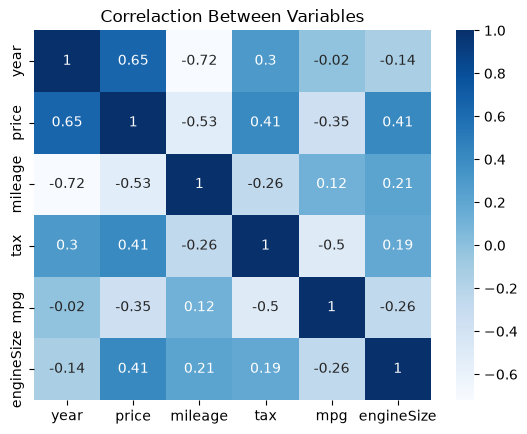

In [27]:
sns.heatmap(df.drop(columns=catColumns).corr(), annot=True, cmap='Blues')
plt.title("Correlaction Between Variables")

In [28]:
mpg_q3 = df["mpg"].describe()["75%"]

print("Number of rows: ", df[df["mpg"] > mpg_q3]["mpg"].shape[0])
df[df["mpg"] > mpg_q3]["mpg"].describe()

Number of rows:  2186


count    2186.000000
mean       73.757685
std         7.970022
min        67.300000
25%        68.900000
50%        74.300000
75%        74.300000
max       201.800000
Name: mpg, dtype: float64

In [29]:
# 201.8 MPG for Kuga 2020 Hybrid is the official MPG by ford
# link: https://www.greencarguide.co.uk/car-reviews-and-road-tests/ford-kuga-phev-review/#:~:text=Our%20test%20showed%20that%20it,the%20official%20201.8%20mpg%20figure.

df[df["mpg"] > 100]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
6153,Kuga,2020,31000,Semi-Auto,10,Hybrid,135,201.8,2.5
6536,Kuga,2020,31991,Semi-Auto,2357,Hybrid,135,201.8,2.5
9220,Kuga,2020,32000,Automatic,10,Hybrid,140,201.8,2.5
12862,Kuga,2020,33500,Automatic,5534,Hybrid,140,201.8,2.5
13730,Kuga,2020,32995,Automatic,11,Hybrid,135,201.8,2.5


In [30]:
df[(df["model"] == "Kuga")]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
8,Kuga,2019,25500,Automatic,6894,Diesel,145,42.2,2.0
13,Kuga,2018,17999,Semi-Auto,9002,Diesel,145,54.3,2.0
14,Kuga,2018,18999,Semi-Auto,8970,Diesel,145,58.9,1.5
15,Kuga,2018,14399,Manual,12810,Diesel,145,64.2,1.5
16,Kuga,2019,17999,Manual,10428,Diesel,145,38.2,2.0
...,...,...,...,...,...,...,...,...,...
17937,Kuga,2018,17999,Automatic,9725,Petrol,145,38.2,1.5
17947,Kuga,2018,17199,Semi-Auto,26000,Diesel,145,54.3,2.0
17948,Kuga,2017,16500,Manual,27367,Diesel,145,54.3,2.0
17949,Kuga,2018,16500,Manual,33646,Diesel,145,60.1,2.0


In [31]:
max_mpg = df.loc[(df["fuelType"] == "Hybrid") & (df["mpg"] != 201.8), "mpg"].max()

df.loc[(df["fuelType"] == "Hybrid") & (df["mpg"] == 201.8), "mpg"] = max_mpg

df["mpg"].describe()

count    17812.000000
mean        57.870941
std          9.842892
min         20.800000
25%         52.300000
50%         58.900000
75%         65.700000
max         88.300000
Name: mpg, dtype: float64

In [32]:
df[(df["model"] == "Kuga") & (df["year"] == 2020)]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
581,Kuga,2020,20450,Manual,1196,Diesel,150,38.2,2.0
4322,Kuga,2020,25490,Manual,1128,Diesel,145,39.2,2.0
6153,Kuga,2020,31000,Semi-Auto,10,Hybrid,135,67.3,2.5
6536,Kuga,2020,31991,Semi-Auto,2357,Hybrid,135,67.3,2.5
9220,Kuga,2020,32000,Automatic,10,Hybrid,140,67.3,2.5
12862,Kuga,2020,33500,Automatic,5534,Hybrid,140,67.3,2.5
13730,Kuga,2020,32995,Automatic,11,Hybrid,135,67.3,2.5
17868,Kuga,2020,25050,Manual,50,Diesel,145,38.2,2.0


In [33]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17812.000000,17812.000000,17812.000000,17812.000000,17812.000000,17812.000000
mean,2016.859870,12269.556310,23381.146362,113.315012,57.870941,1.350623
std,2.026469,4736.285417,19419.011045,62.034603,9.842892,0.432581
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,10000.000000,30.000000,52.300000,1.000000
50%,2017.000000,11288.000000,18277.000000,145.000000,58.900000,1.200000
75%,2018.000000,15295.000000,31098.500000,145.000000,65.700000,1.500000
max,2020.000000,54995.000000,177644.000000,580.000000,88.300000,5.000000


In [34]:
tax_q3 = df["tax"].describe()["75%"]

print("Number of rows: ", df[df["tax"] > tax_q3]["tax"].shape[0])
df[df["tax"] > tax_q3]["tax"].describe()

Number of rows:  2974


count    2974.000000
mean      166.765299
std        39.204511
min       150.000000
25%       150.000000
50%       150.000000
75%       160.000000
max       580.000000
Name: tax, dtype: float64

In [35]:
df[df["tax"] > 200]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
75,Kuga,2017,17920,Automatic,15815,Petrol,235,38.2,1.5
91,Focus,2016,24995,Manual,7997,Petrol,235,36.7,2.3
104,Kuga,2017,13998,Automatic,13265,Petrol,240,38.2,1.5
364,Mustang,2016,24999,Semi-Auto,42086,Petrol,570,23.5,5.0
373,Focus,2015,13998,Manual,35689,Petrol,205,41.5,2.0
...,...,...,...,...,...,...,...,...,...
17761,Focus,2005,2495,Automatic,87908,Petrol,265,36.7,1.6
17769,Kuga,2014,11995,Automatic,21282,Petrol,265,36.7,1.6
17792,Kuga,2016,17000,Automatic,7016,Petrol,235,38.2,1.5
17803,Kuga,2017,18000,Automatic,1272,Petrol,235,38.2,1.5


In [36]:
df = df[df["tax"] <= 200]

df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17501.000000,17501.000000,17501.000000,17501.000000,17501.000000,17501.000000
mean,2016.926747,12280.573967,22959.141592,110.843495,58.206605,1.340421
std,1.910214,4689.434807,18836.112500,59.025366,9.569315,0.421898
min,1998.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9937.000000,30.000000,53.300000,1.000000
50%,2017.000000,11250.000000,18040.000000,145.000000,58.900000,1.200000
75%,2018.000000,15290.000000,30738.000000,145.000000,65.700000,1.500000
max,2020.000000,54995.000000,177644.000000,200.000000,88.300000,5.000000


In [37]:
q1_price = df['price'].quantile(0.25)
q3_price = df['price'].quantile(0.75)
iqr_price = q3_price - q1_price

q1_mileage = df['mileage'].quantile(0.25)
q3_mileage = df['mileage'].quantile(0.75)
iqr_mileage = q3_mileage - q1_mileage

filter = (
    (df['price'] >= q1_price - 1.5 * iqr_price) &
    (df['price'] <= q3_price + 1.5 * iqr_price) &
    (df['mileage'] >= q1_mileage - 1.5 * iqr_mileage) &
    (df['mileage'] <= q3_mileage + 1.5 * iqr_mileage)
)

df[~filter]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
8,Kuga,2019,25500,Automatic,6894,Diesel,145,42.2,2.0
76,Fiesta,2013,4790,Manual,74128,Petrol,0,65.7,1.0
230,S-MAX,2020,34498,Semi-Auto,4623,Diesel,145,43.5,2.0
254,Fiesta,2013,4998,Manual,79300,Petrol,0,65.7,1.0
288,Fiesta,2014,4699,Manual,85000,Petrol,30,54.3,1.2
...,...,...,...,...,...,...,...,...,...
17868,Kuga,2020,25050,Manual,50,Diesel,145,38.2,2.0
17890,Edge,2018,25999,Automatic,19458,Diesel,145,47.9,2.0
17903,Focus,2020,24999,Manual,4900,Petrol,145,34.5,2.3
17906,Kuga,2017,15499,Semi-Auto,64315,Diesel,145,54.3,2.0


In [38]:
df = df[filter]
print(df.shape)
df.describe()

(16417, 9)


,year,price,mileage,tax,mpg,engineSize
count,16417.000000,16417.000000,16417.000000,16417.000000,16417.000000,16417.000000
mean,2017.083389,12293.776086,20397.383992,111.858561,58.436060,1.310160
std,1.638706,4014.574410,13796.975651,58.129807,9.168792,0.378242
min,1998.000000,1294.000000,1.000000,0.000000,28.800000,0.000000
25%,2016.000000,9300.000000,9836.000000,30.000000,54.300000,1.000000
50%,2017.000000,11490.000000,17407.000000,145.000000,58.900000,1.100000
75%,2018.000000,15290.000000,28971.000000,145.000000,65.700000,1.500000
max,2020.000000,24690.000000,61904.000000,200.000000,88.300000,2.300000


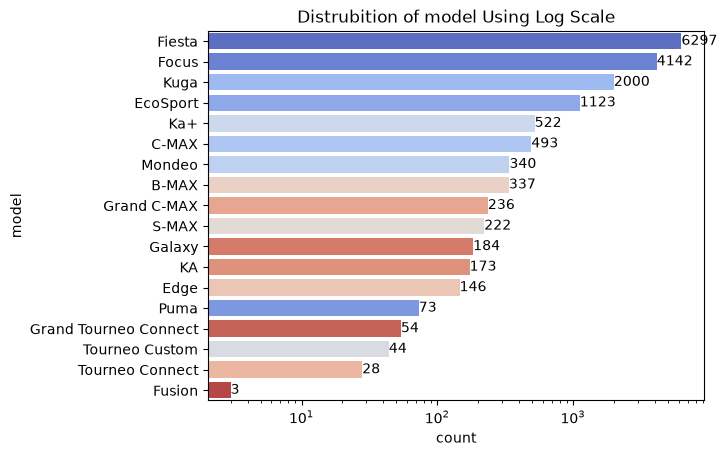

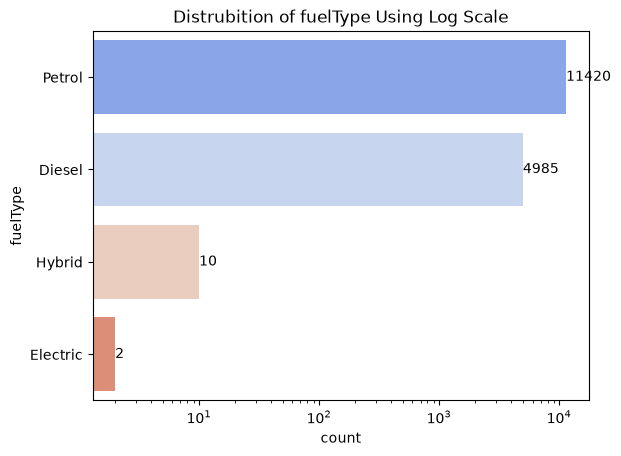

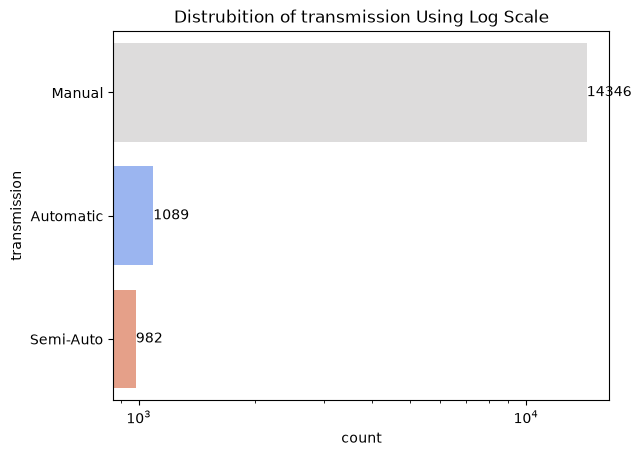

In [39]:
for c in catColumns:
    ax = sns.countplot(data=df, y=c, hue=c, palette="coolwarm", order=df[c].value_counts().index)
    ax.set_xscale("log")
    ax.set_title("Distrubition of " + c + " Using Log Scale")
    
    for container in ax.containers:
        ax.bar_label(container)
    
    plt.show()

Text(0.5, 1.0, 'Correlaction Between Variables')

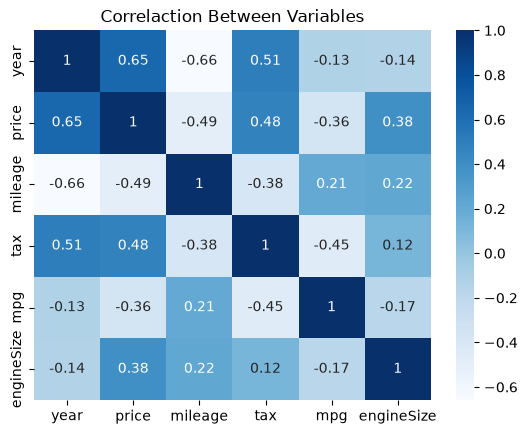

In [40]:
sns.heatmap(df.drop(columns=catColumns).corr(), annot=True, cmap='Blues')
plt.title("Correlaction Between Variables")

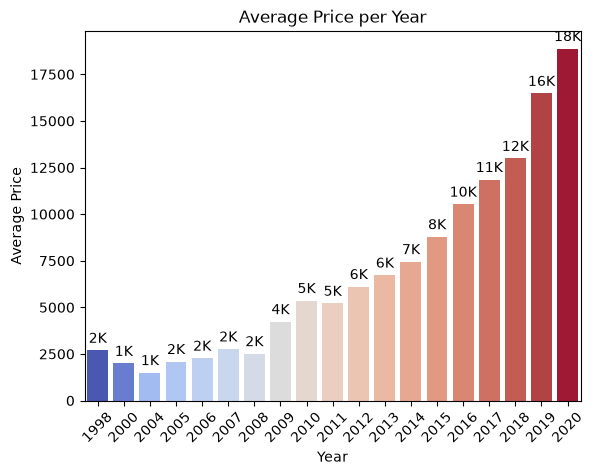

In [41]:
avg_price_per_year = df.groupby("year")["price"].mean().reset_index()

ax = sns.barplot(data=avg_price_per_year, x="year", y="price", hue="year", palette="coolwarm", legend=False)
plt.xticks(rotation=45)
plt.title("Average Price per Year")
plt.xlabel("Year")
plt.ylabel("Average Price")

for container in ax.containers:
    ax.bar_label(container, label_type="edge", padding=3, fontsize=10,
                 labels=[f'{int(v.get_height()/1000)}K' for v in container])

plt.show()

In [42]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [43]:
df["price"] = np.log(df["price"])
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,16417.000000,16417.000000,16417.000000,16417.000000,16417.000000,16417.000000
mean,2017.083389,9.362512,20397.383992,111.858561,58.436060,1.310160
std,1.638706,0.334910,13796.975651,58.129807,9.168792,0.378242
min,1998.000000,7.165493,1.000000,0.000000,28.800000,0.000000
25%,2016.000000,9.137770,9836.000000,30.000000,54.300000,1.000000
50%,2017.000000,9.349232,17407.000000,145.000000,58.900000,1.100000
75%,2018.000000,9.634954,28971.000000,145.000000,65.700000,1.500000
max,2020.000000,10.114154,61904.000000,200.000000,88.300000,2.300000


In [44]:
df = pd.get_dummies(df, columns=catColumns, drop_first=True)

In [45]:
X = df.drop(columns=["price"])
Y = df[["price"]]

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=10)
feature_columns = X.columns

In [46]:
lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred = lr.predict(x_test)

In [47]:
y_pred = np.exp(y_pred)
y_test  = np.exp(y_test)

In [48]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("Mean Square Errors: ", mse)
print("Root Mean Square Errors: ", rmse)
print(f"MAPE: {mape * 100:.2f}%")

Mean Square Errors:  2128952.931505111
Root Mean Square Errors:  1459.0931880812518
MAPE: 9.38%


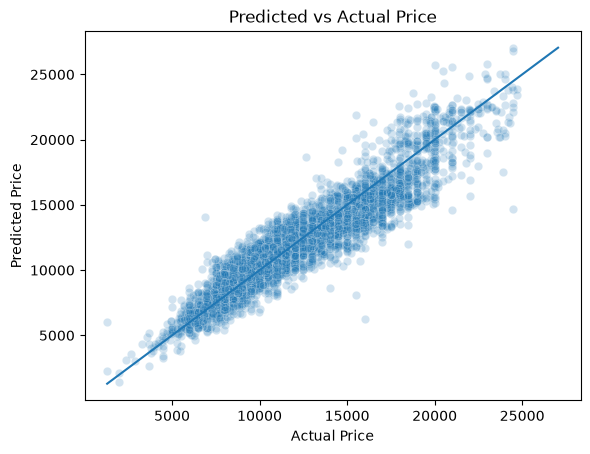

In [49]:
y_test = np.ravel(y_test)
y_pred = np.ravel(y_pred)

plt.figure()
sns.scatterplot(x=y_test, y=y_pred, alpha=0.2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual Price")

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims)
plt.show()

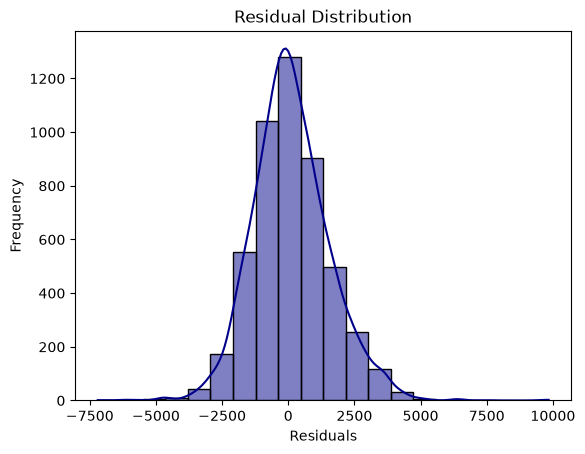

In [50]:
residuals = y_test - y_pred

sns.histplot(residuals, kde=True, color='darkblue', bins=20)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()

In [51]:
joblib.dump(lr, "car_price_model.pkl")
joblib.dump(feature_columns, "model_features.pkl")

['model_features.pkl']